# 05 - Aprendizado em conjunto

Foram avaliados Random Forest e Gradient Boosting para regressão e classificação. O primeiro combina árvores treinadas com aleatoriedade; o segundo constrói estimadores sequencialmente. Os hiperparâmetros são ajustados por validação cruzada no treinamento, com análise da importância das variáveis e da evolução do erro em função do número de árvores.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT/'data').exists(): ROOT = ROOT.parent
assert (ROOT/'src').exists(), 'Abra o notebook a partir da pasta do projeto.'
sys.path.insert(0,str(ROOT))
TAB=ROOT/'reports'/'tables'; FIG=ROOT/'reports'/'figures'
META=json.loads((ROOT/'data/processed/metadata.json').read_text(encoding='utf-8'))
print('Projeto:', ROOT)

Projeto: C:\Users\Felipe Erik\Desktop\Trabalho2IA\final\student_career_ia


## Treinamento e validação
Nesta etapa são ajustados os modelos com o conjunto de treinamento e validação cruzada K-fold. Os parâmetros e as métricas da execução são salvos na pasta de tabelas.

In [2]:
from src.training import train_group

# Execução independente do treinamento para regressão e classificação.
# Busca de parâmetros e validação cruzada são feitas somente sobre o treino.
for tarefa in ('regression', 'classification'):
    resultados = train_group(tarefa, ['Random_Forest', 'Gradient_Boosting'])
    display(resultados.round(4))

regression: Random_Forest | ajuste 260.57 s
regression: Gradient_Boosting | ajuste 428.01 s


,task,model,split,MAE,MSE,RMSE,MAPE,R2,MedAE
0,regression,Random_Forest,train,0.9581,1.6743,1.2939,0.4702,0.9977,0.7272
1,regression,Random_Forest,test,2.0608,7.7013,2.7751,1.0164,0.9893,1.5477
2,regression,Gradient_Boosting,train,2.0948,7.7666,2.7869,1.0315,0.9892,1.6103
3,regression,Gradient_Boosting,test,2.1064,7.8456,2.8010,1.0376,0.9891,1.6130


classification: Random_Forest | ajuste 50.05 s
classification: Gradient_Boosting | ajuste 223.81 s


,task,model,split,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,classification,Random_Forest,train,0.8358,0.8485,0.9614,0.9014,0.8744,0.9573
1,classification,Random_Forest,test,0.8177,0.8400,0.9468,0.8902,0.8034,0.9193
2,classification,Gradient_Boosting,train,0.8219,0.8403,0.9530,0.8931,0.8149,0.9202
3,classification,Gradient_Boosting,test,0.8188,0.8408,0.9472,0.8909,0.8059,0.9164


In [3]:
import pickle

def load_model(task, name):
    # Deserializar SOMENTE os modelos do próprio projeto / fonte confiável.
    path=ROOT/'models'/f'{task}_{name}.pkl'
    with path.open('rb') as f: return pickle.load(f)

## Busca por hiperparâmetros e comparação

In [4]:
from src.models import model_specs
p=json.loads((TAB/'best_parameters.json').read_text(encoding='utf8'))
for task in ['regression','classification']:
    print('\n',task)
    for method in ['Random_Forest','Gradient_Boosting']:
        print(method, 'grade:',model_specs(task=='classification','standard')[method][1],'melhor:',p.get(f'{task}:{method}'))
m=pd.read_csv(TAB/'model_metrics.csv')
display(m[(m.split=='test') & (m.model.isin(['Random_Forest','Gradient_Boosting']))].round(4))


 regression
Random_Forest grade: {'model__n_estimators': [40, 100], 'model__max_depth': [10, 16], 'model__min_samples_leaf': [2]} melhor: {'model__max_depth': 16, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Gradient_Boosting grade: {'model__n_estimators': [60, 100], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2]} melhor: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}

 classification
Random_Forest grade: {'model__n_estimators': [40, 100], 'model__max_depth': [10, 16], 'model__min_samples_leaf': [2]} melhor: {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Gradient_Boosting grade: {'model__n_estimators': [60, 100], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2]} melhor: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 60}


,task,model,split,MAE,MSE,RMSE,MAPE,R2,MedAE,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
7,regression,Random_Forest,test,2.0608,7.7013,2.7751,1.0164,0.9893,1.5477,NaN,NaN,NaN,NaN,NaN,NaN
9,regression,Gradient_Boosting,test,2.1064,7.8456,2.8010,1.0376,0.9891,1.6130,NaN,NaN,NaN,NaN,NaN,NaN
17,classification,Random_Forest,test,NaN,NaN,NaN,NaN,NaN,NaN,0.8177,0.8400,0.9468,0.8902,0.8034,0.9193
19,classification,Gradient_Boosting,test,NaN,NaN,NaN,NaN,NaN,NaN,0.8188,0.8408,0.9472,0.8909,0.8059,0.9164


## Curva de erro × número de árvores
A curva foi construída com um subconjunto de validação separado apenas do treino, para não escolher hiperparâmetros olhando o conjunto de teste.

regression


,trees,error
0,1,5.385722
1,10,3.427689
2,50,3.225431
3,100,3.200856
4,200,3.198445


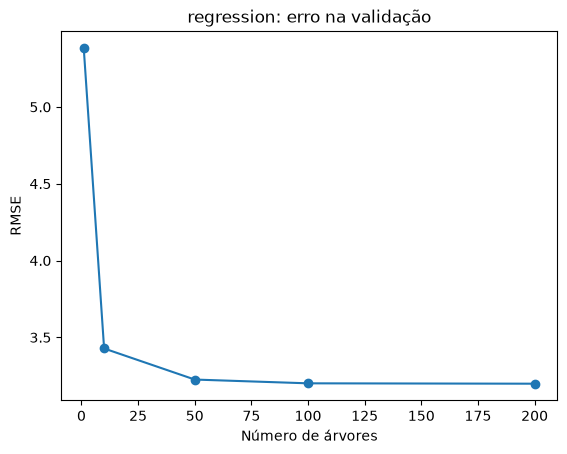

classification


,trees,error
0,1,0.129610
1,10,0.110777
2,50,0.106386
3,100,0.105476
4,200,0.106007


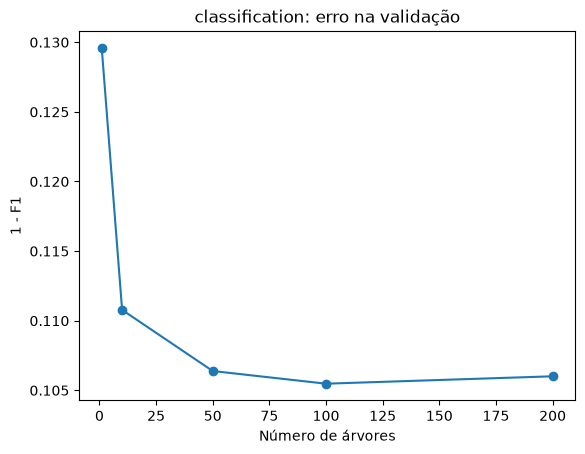

In [5]:
for task in ['regression','classification']:
    curve=pd.read_csv(TAB/f'{task}_rf_curve.csv'); print(task); display(curve)
    ax=curve.plot(x='trees',y='error',marker='o',legend=False,title=f'{task}: erro na validação')
    ax.set(xlabel='Número de árvores',ylabel='1 - F1' if task=='classification' else 'RMSE');plt.show()

## Importância das features
As importâncias por redução de impureza não provam causalidade e podem favorecer certos tipos de atributos. A comparação com as variáveis da base de regras permite avaliar a concordância entre os critérios.

regression


,feature,importance
0,num__Resume_Score,0.6386
1,num__Programming_Skill,0.1030
2,num__Interview_Score,0.0948
3,num__Internships,0.0649
4,num__Problem_Solving,0.0469
5,num__CGPA,0.0271
6,num__Projects_Completed,0.0106
7,num__Communication_Skills,0.0045
8,num__Certifications,0.0029
9,num__Attendance_Percentage,0.0012


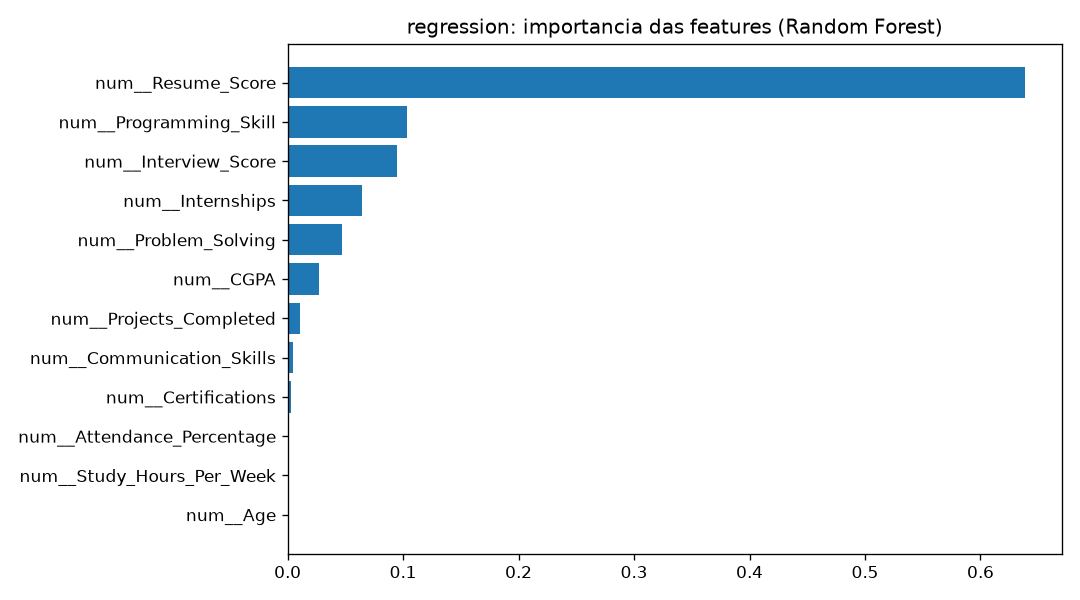

classification


,feature,importance
0,num__Employability_Score,0.2453
1,num__Resume_Score,0.1390
2,num__Interview_Score,0.0993
3,num__Problem_Solving,0.0746
4,num__Internships,0.0666
5,num__Programming_Skill,0.0625
6,num__Projects_Completed,0.0511
7,num__CGPA,0.0389
8,num__Communication_Skills,0.0278
9,cat__English_Proficiency_Advanced,0.0249


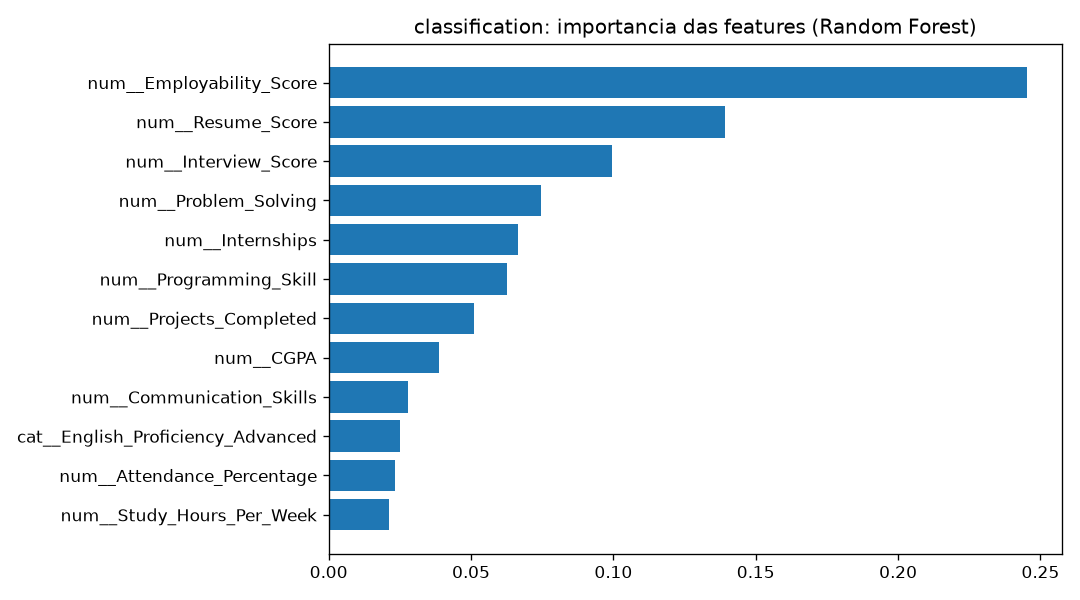

In [6]:
for task in ['regression','classification']:
    imp=pd.read_csv(TAB/f'{task}_feature_importance.csv')
    print(task);display(imp.head(12).round(4))
    display(Image(filename=str(FIG/f'{task}_feature_importance.png')))

## Interpretação
A seleção entre RF e Boosting considera conjuntamente métricas de teste, dispersão da validação cruzada e custo computacional. Uma diferença pequena de F1 ou RMSE, isoladamente, não comprova superioridade estatística.